In [1]:
import os, sys

try:
  os.chdir('../Rで学ぶベイズ統計学入門')
except:
  pass

path = os.getcwd()

In [2]:
print("Python:", sys.executable)

Python: /Users/takanohiroshi/myenv/bin/python


In [3]:
#pip uninstall numpy pandas scipy -y

In [4]:
#pip install numpy==1.26.4 pandas==2.1.4 scipy==1.11.4

In [5]:
import numpy
import pandas


print("NumPy:", numpy.__version__)
print("pandas:", pandas.__version__)



NumPy: 1.26.4
pandas: 2.1.4


In [6]:
#pip freeze > requirements.txt

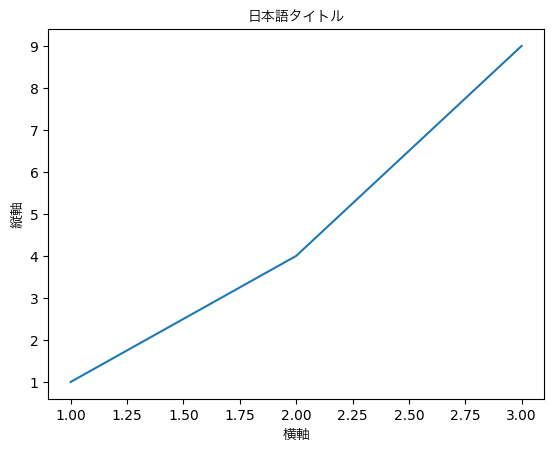

In [7]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 日本語フォント指定（Macの例）
font_path = "/System/Library/Fonts/ヒラギノ角ゴシック W3.ttc"
font_prop = fm.FontProperties(fname=font_path)

plt.title("日本語タイトル", fontproperties=font_prop)
plt.xlabel("横軸", fontproperties=font_prop)
plt.ylabel("縦軸", fontproperties=font_prop)

plt.plot([1,2,3], [1,4,9])
plt.show()

In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import japanize_matplotlib

from scipy.stats import beta, binom, betabinom, norm, t



### 3.2 平均が既知で分散が未知の正規分布

差が、平均０で未知分布 $ \sigma^2 $ の正規分布からのランダムな標本だとすると、尤度関数は下記の式で与えられる。

正規分布の確率密度：

$ f(d_i| \sigma^2) = 1/\sqrt{2 \pi \sigma^2} exp(-d_i^2/2 \sigma^2) $

尤度関数：

$ L(\sigma^2) \propto (\sigma^2)^{-n/2} exp\bigl\{ -\sum_{i=1}^n d_i^2 / (2\sigma^2) \bigr\} \qquad (\sigma^2 > 0)$

＊尤度推定（MLE）では、比例で扱うので定数はすべて削除して良い。

ここで、分散に無情報事前密度 $ P = 1/ \sigma^2 $ を割り当てるとする。これは分散に対する標準的な曖昧事前分布

$ g(\sigma^2 | data) \propto (\sigma^2)^{-n/(2+1)} exp\bigl\{ -v / (2\sigma^2) \bigr\}  $
$ \qquad v = \sum_{i=1}^n d_i^2 $

$ P = 1/\sigma^2 $ とすると、精度パラメータPはU/vとして分布する。Uは自由度nのカイ事情分布に従う。

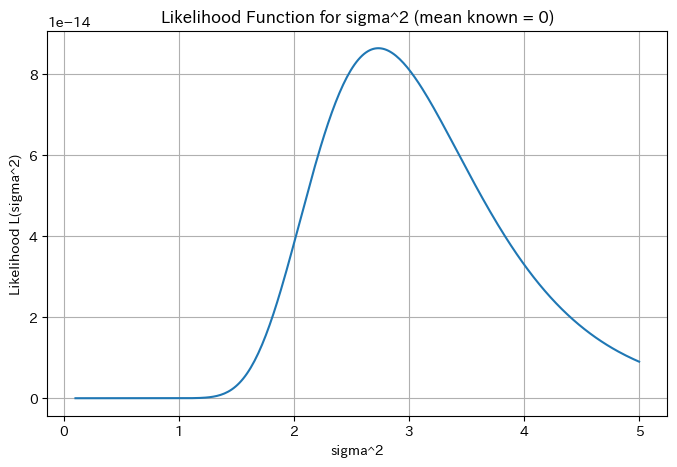

In [9]:
# Example data: differences d_i
# Let's create sample differences generated from N(0, true_sigma^2)
np.random.seed(0)
true_sigma2 = 2.0
n = 30
d = np.random.normal(0, np.sqrt(true_sigma2), size=n)

# Likelihood function for sigma^2 (up to proportionality)
def likelihood_sigma2(s2, d):
    n = len(d)
    return s2**(-n/2) * np.exp(-np.sum(d**2) / (2*s2))

# Range of sigma^2 to evaluate
s2_values = np.linspace(0.1, 5, 300)
L_values = np.array([likelihood_sigma2(s2, d) for s2 in s2_values])

# Plot
plt.figure(figsize=(8,5))
plt.plot(s2_values, L_values)
plt.xlabel("sigma^2")
plt.ylabel("Likelihood L(sigma^2)")
plt.title("Likelihood Function for sigma^2 (mean known = 0)")
plt.grid(True)
plt.show()


Text(0.5, 1.0, '図3.1 試合結果とポイント・スプレッドの差の標準偏差$\\sigma$をシュミレーションした表本のヒストグラム')

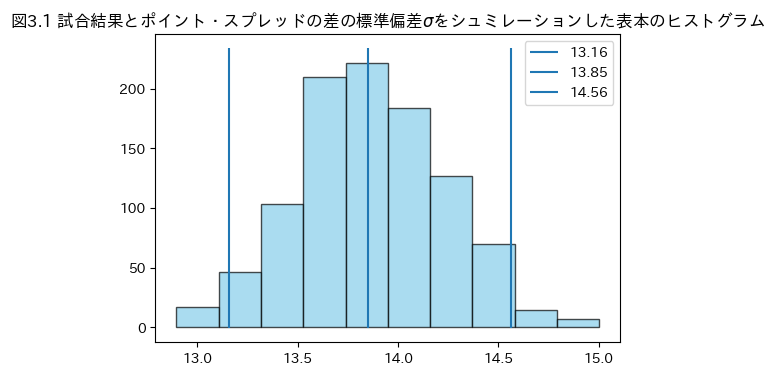

In [10]:
np.random.seed(0)

df = pd.read_csv("footballscores.csv", sep=",")
df.columns = df.columns.str.replace(".","_")
df["d"] = df["favorite"].astype(float) - df["underdog"].astype("float") - df["spread"].astype("float")
df["v"] = df["d"]**2
n = len(df)

x = np.random.chisquare(n, 1000)/df["v"].sum()
x = np.sqrt(1/x)

c_array = np.percentile(x, q=[2.5, 50, 97.5])

fig, ax1 = plt.subplots(figsize=(6,4))
ax1. hist(x, bins= 10, density=False, alpha=0.7, color="skyblue", edgecolor="black")


vmin, vmax = ax1.get_ylim()
for each in c_array:
    ax1.vlines(each, vmin-1, vmax+1, label=f"{each:.2f}")
ax1.legend()

ax1.set_title(r"図3.1 試合結果とポイント・スプレッドの差の標準偏差$\sigma$をシュミレーションした表本のヒストグラム")


In [11]:
df["d"].mean()

0.06994047619047619

### 3,3 心臓移植手術の死亡率を推定する



In [12]:
from scipy.stats import poisson, gamma, gaussian_kde

alpha = 16
beta = 15174
yobs = 1
ex = 66

y = np.arange(0,11)

lam = alpha/beta

py = poisson.pmf(y, mu=lam*ex) \
    * gamma.pdf(lam, a=alpha, scale=1/beta) \
    / gamma.pdf(lam, a=alpha+y, scale=1/(beta+ex))

result = np.column_stack([y, np.round(py,3)]) 

for yi, pyi in zip(y,py):
    print(f"{yi:2d}  {pyi:.3f}")

# Lambda samples (same as before)
shape = alpha + yobs
rate = beta + ex
lambdaA = np.random.gamma(shape=shape, scale=1/rate, size=1000)


 0  0.933
 1  0.065
 2  0.002
 3  0.000
 4  0.000
 5  0.000
 6  0.000
 7  0.000
 8  0.000
 9  0.000
10  0.000


In [13]:
yobs = 4
ex = 1767

py = poisson.pmf(y, mu=lam*ex) \
    * gamma.pdf(lam, a=alpha, scale=1/beta) \
    / gamma.pdf(lam, a=alpha+y, scale=1/(beta+ex))

result = np.column_stack([y, np.round(py,3)]) 

for yi, pyi in zip(y,py):
    print(f"{yi:2d}  {pyi:.3f}")

# Lambda samples (same as before)
shape = alpha + yobs
rate = beta + ex
lambdaB = np.random.gamma(shape=shape, scale=1/rate, size=1000)

 0  0.172
 1  0.286
 2  0.254
 3  0.159
 4  0.079
 5  0.033
 6  0.012
 7  0.004
 8  0.001
 9  0.000
10  0.000


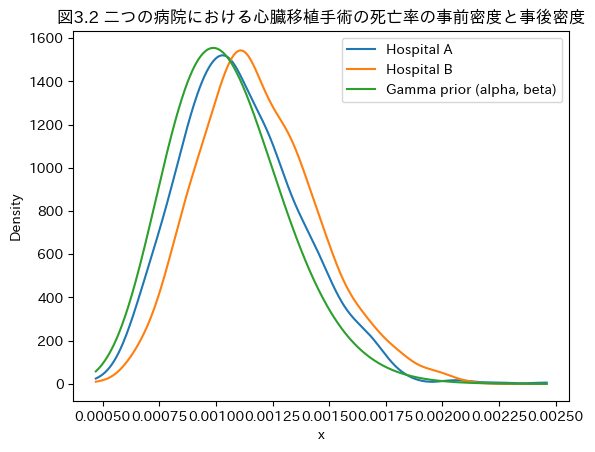

In [14]:
# Density estimate (density(lambdaA))
kde = gaussian_kde(lambdaA)
x_vals = np.linspace(lambdaA.min(), lambdaA.max(), 400)
density_vals = kde(x_vals)

# Density estimate (density(lambdaB))
kde_B = gaussian_kde(lambdaB)
density_vals_B = kde_B(x_vals)


# Gamma prior curve (R: curve(dgamma(x, shape=alpha, rate=beta)))
gamma_vals = gamma.pdf(x_vals, a=alpha, scale=1/beta)

plt.figure()

# Plot density of lambdaA
plt.plot(x_vals, density_vals, label="Hospital A")
plt.plot(x_vals, density_vals_B, label="Hospital B")

# Add gamma prior curve
plt.plot(x_vals, gamma_vals, label="Gamma prior (alpha, beta)")

plt.xlabel("x")
plt.ylabel("Density")
plt.title("図3.2 二つの病院における心臓移植手術の死亡率の事前密度と事後密度")
plt.legend()
plt.show()


### 3.4 ベイズ法の眼瞼性について

事前の確信に適合する異なる事前分布が多数存在しても、推論がその違いによる影響を受けない場合に、ベイズ分析は事前分布の選択に対して**頑健**であると言われる。



ジョーという人物の知能指数（IQ）$ \theta $ の真の値を推定したい。
ジョーの知能指数は平均的であり、その事前分布の中央値は100であると考える。
ジョーのIQは 80 と 120 の間にあることに 90% の確信があるとする。

この確信に適合する正規密度の平均値と標準編背を求めよ。

In [15]:
from scipy.stats import norm

# 与えられた条件
mu = 100  # 中央値（平均）
lower = 80
upper = 120
p = 0.90  # 確率

# 90% 中央区間なら、両側5% → 95パーセント点 z
z = norm.ppf(0.95)

# 標準偏差の計算
sigma = (upper - mu) / z

print("平均 mu =", mu)
print(f"z(0.95) =, {z:.2f}")
print(f"標準偏差 sigma =, {sigma:.2f}")


平均 mu = 100
z(0.95) =, 1.64
標準偏差 sigma =, 12.16


ジョーは４回のIQテストを受け、そのスコアが $ y_1, y_2, y_3, y_4 $ とする。

それぞれのスコア $ y $ の分布が、既知の標準偏差　$ \sigma = 15 $ の正規分布 $ N(\theta, \sigma) $ に従うと仮定する。

ここで、ジョーのテスト結果として三つのケースを想定して、その事後計算の方法を示す。

観測されるテストスコアの平均を仮に $ \bar{y} = 110, \bar{y} = 125, \bar{y} = 140 $ とし、それぞれの場合についてジョーの真の IQ $ \theta $ の事後平均と標準偏差を計算する。

正規事前密度を使うので、$ \theta $ の事後密度も正規関数形となる。

精度が分散の逆数として定義される。

事後の精度 $ P_1 = 1/\tau_1^2 $ は、データの精度 $ P_D = n/ \sigma^2 $ と事前の精度 $ P = 1/ \tau^2 $ の和になる。

$ P_1 = P_D + P = 4/ \sigma^2 + 1/ \tau^2 $

事後の標準偏差は、$ \tau_1 = 1 / \sqrt{P_1} $

$ \theta $ の事後平均は標本平均と事前平均の加重平均になる。


In [16]:
# ----- 事前分布のパラメータ -----
mu0 = 100              # 事前平均
sigma0 = 12.16         # 事前標準偏差（前問の結果）

# ----- 観測モデル -----
sigma = 15             # y_i の既知標準偏差
n = 4                  # 観測回数

# ----- 観測平均のケース -----
ybar_list = [110, 125, 140]

def posterior(mu0, sigma0, ybar, sigma, n):
    """正規×正規の事後平均と事後標準偏差を返す"""
    precision_prior = 1 / sigma0**2
    precision_likelihood = n / sigma**2
    
    mu1 = (mu0 * precision_prior + ybar * precision_likelihood) / (precision_prior + precision_likelihood)

    sigma1 = np.sqrt(1 / (precision_prior + precision_likelihood))
    
    return mu1, sigma1

# ----- 結果の表示 -----
df = pd.DataFrame({
    "ybar": pd.Series(dtype=float),
    "mu1": pd.Series(dtype=float),
    "tau1": pd.Series(dtype=float)
})

for ybar in ybar_list:
    mu1, sigma1 = posterior(mu0, sigma0, ybar, sigma, n)
    df = pd.concat([df, pd.DataFrame({"ybar":[ybar], "mu1":[mu1], "tau1":[sigma1]})], ignore_index=True)

print(df)

summ1 = df
mu1 = summ1["mu1"]
tau1 = summ1["tau1"]


    ybar         mu1      tau1
0  110.0  107.244209  6.383469
1  125.0  118.110522  6.383469
2  140.0  128.976835  6.383469


ジョーの真のIQについての確信をモデル化するのに、別の事前密度を検討する。

位置バラメータ $ \mu $、尺度パラメータ $ \tau $、自由度 2 のt密度を利用する。

$ \mu = 100 $　とし、$ \theta $ の 95% 分位点が 120 であるとき、$ \tau $ を求める。

In [17]:


mu = 100        # 位置パラメータ
df = 2          # 自由度
q95 = 120       # 95% 分位点として与えられた値

# t 分布の 95% 点
t95 = t.ppf(0.95, df)

# τ の計算
tau = (q95 - mu) / t95

print(f"t_0.95(df=2) = {t95:.2f}")
print(f"求める τ = {tau:.6f}")


t_0.95(df=2) = 2.92
求める τ = 6.849349


In [18]:
mu = 100
df = 2

# t分布（自由度df=2）の95パーセント点
t_95 = t.ppf(0.95, df=df)

# 尺度パラメータtauの計算
tau = (120 - mu) / t_95

print(f"尺度パラメータを求める τ = {tau:.6f}")

尺度パラメータを求める τ = 6.849349


グラフの見方
# 100
分布の中心（１００）

# 120
右側の９５％分位点

# 裾野が非常に厚い
極端な値も完全には否定しない



Text(0.5, 1.0, '図3.3 自由度2、尺度パラメータτ=6.849のt分布による事前密度')

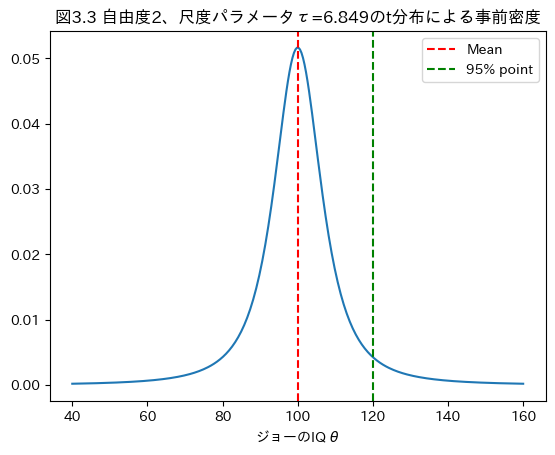

In [19]:
theta = np.linspace(40, 160, 300)

density = t.pdf((theta - mu) /tau, df)/tau

plt.figure()
plt.plot(theta, density)
plt.axvline(mu, color="red", linestyle="--", label="Mean")
plt.axvline(120, color="green", linestyle="--", label="95% point")
plt.legend()
plt.xlabel(r"ジョーのIQ $\theta$")
plt.title(r"図3.3 自由度2、尺度パラメータτ={:.3f}のt分布による事前密度".format(tau))

正規事前密度とt事前密度を同一のグラフに示す。

テストスコアが極端な値の場合、事後密度に影響がある
* 中央値付近（９０〜110）
正規分布とt分布はほぼ同じ高さ：だいたい１００前後だろうという認識は同じ

* 両端（６０以下、１４０以上）
t分布の方が明らかに高い：t分布はかなり高い/かなり低いIQも、完全には否定しない。

→ t分布は不確実性がおおきいという意味。

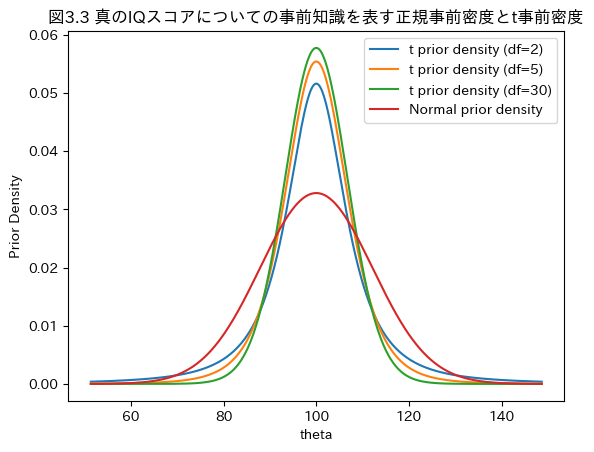

In [20]:
sigma = 10

# Range for plotting
x = np.linspace(mu - 4*sigma0, mu + 4*sigma0, 500)

dfs = [2,5, 30]
for df in dfs:
    plt.plot(x, t.pdf((x - mu)/tau, df) / tau, label=f"t prior density (df={df})")  

plt.plot(x, norm.pdf(x, mu, sigma0), label="Normal prior density")

plt.xlabel("theta")
plt.ylabel("Prior Density")
plt.legend()
plt.title("図3.3 真のIQスコアについての事前知識を表す正規事前密度とt事前密度")
plt.show()


表本のそれぞれについてt事前密度を使って事後密度を計算する。
$ \theta $ の事後密度

$ g(\theta | data) \propto  \phi( \bar{y} | \theta, \sigma / \sqrt{n}) g_T ( \theta | v, \mu, \tau) $
)

In [21]:
def norm_t_compute(ybar:float, sigma:float, n:int, mu:float, tscale:float, df:int=2):
    # θ のグリッド
    theta = np.linspace(60, 180, 500)

    # 正規尤度
    like = norm.pdf(theta, loc=ybar, scale=sigma / np.sqrt(n))

    # t 分布事前
    prior = t.pdf((theta - mu) / tscale, df) / tscale

    # 事後分布（非正規化）
    post = prior * like

    # 正規化
    post = post / post.sum()

    # 事後平均
    m = np.sum(theta * post)

    # 事後標準偏差
    s = np.sqrt(np.sum(theta**2 * post) - m**2)

    return ybar, m, s

In [22]:
# ybar のリスト
ybar_list = [110, 125, 140]

# 結果を格納
rows = []

for ybar in ybar_list:
    ybar_val, m, s = norm_t_compute(
        ybar=ybar,
        sigma=15,
        n=4,
        mu=100,
        tscale=6.85,  # 以前求めた τ
        df=2
    )
    rows.append([ybar_val, m, s])

# DataFrame 化
summ2 = pd.DataFrame(rows, columns=["ybar", "mu1 t", "tau1 t"])

print(summ2)


   ybar       mu1 t    tau1 t
0   110  105.292415  5.841821
1   125  118.084538  7.885083
2   140  135.413520  7.973464


summ1とsumm2を結合して、二つの事前密度を利用した $ \theta $ の事後積率を比較する。



In [23]:
result = summ1.merge(summ2, on="ybar")
result

,ybar,mu1,tau1,mu1 t,tau1 t
0,110.0,107.244209,6.383469,105.292415,5.841821
1,125.0,118.110522,6.383469,118.084538,7.885083
2,140.0,128.976835,6.383469,135.413520,7.973464


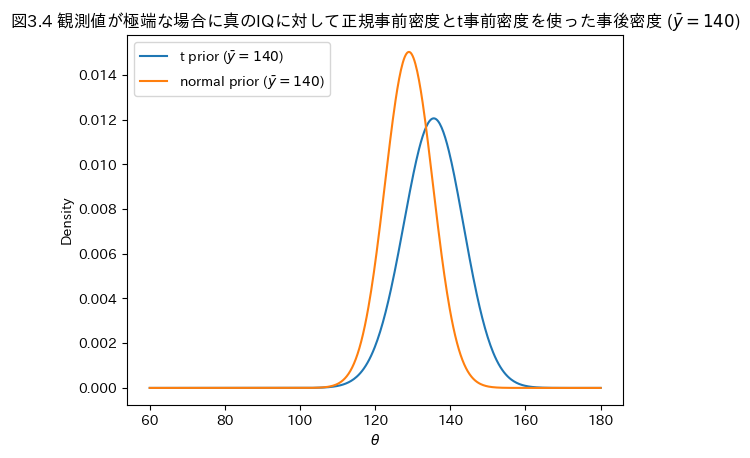

In [24]:
# ---- parameters ----
ybar = 140
sigma = 15
n = 4

mu = 100
tscale = 6.85
df = 2

# ---- theta grid ----
theta = np.linspace(60, 180, 500)

# ---- prior (t distribution) ----
prior = t.pdf((theta - mu) / tscale, df) / tscale

# ---- likelihood (normal for sample mean) ----
like = norm.pdf(theta, loc=ybar, scale=sigma / np.sqrt(n))

# ---- posterior (grid approximation) ----
post = prior * like
post = post / post.sum()

# ---- prior 2: normal prior centered at ybar ----
post_norm = norm.pdf(theta, loc=mu1[2], scale=tau1[2])
post_norm = post_norm / post_norm.sum()

# ---- plot ----
plt.figure()
plt.plot(theta, post, label=r"t prior ($ \bar{y} = 140 $)")
plt.plot(theta, post_norm, label=r"normal prior ($ \bar{y} = 140 $)")

plt.xlabel(r"$\theta$")
plt.ylabel("Density")
plt.title(r"図3.4 観測値が極端な場合に真のIQに対して正規事前密度とt事前密度を使った事後密度 ($ \bar{y} = 140 $)")
plt.legend()
plt.show()


In [25]:
#%pip install -U numpy

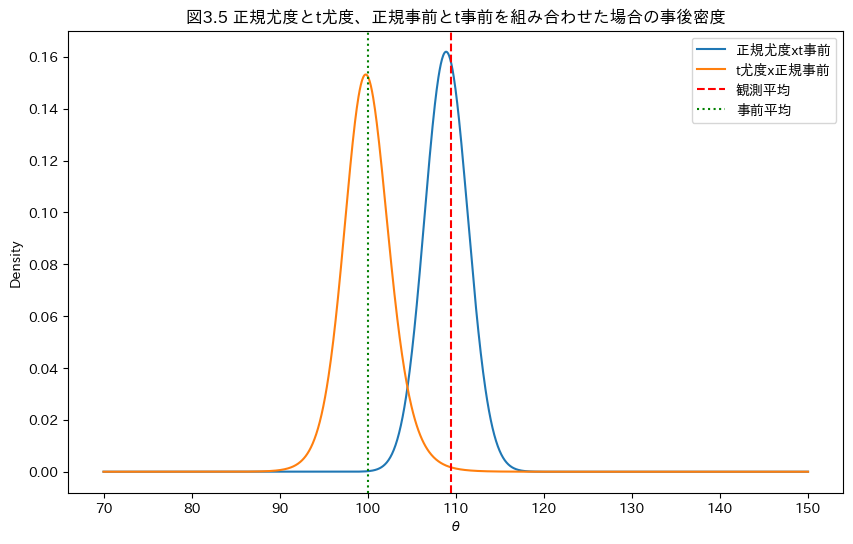

In [26]:
# 観測データ（４回のIQテスト）
data = np.array([98, 101, 99, 140])

# θ のグリッド
theta = np.linspace(70,150, 1200)


# 事前分布
# 正規事前（IQ尺度は信頼する）
prior_normal = norm.pdf(theta, loc=100, scale=10)

# t事前（IQ尺度はあまり信頼しない）
prior_t = t.pdf((theta - 100)/10, df=2)/10

# 尤度関数
def normal_likelihood(theta, data, sigma=5):
    lik = np.ones_like(theta)
    for y in data:
        lik *= norm.pdf(y, loc=theta, scale=sigma)
    return lik

def t_likelihood(theta, data, sigma=5, df=2):
    lik = np.ones_like(theta)
    for y in data:
        lik *= t.pdf((y - theta)/sigma, df=df)/sigma
    return lik

lik_normal = normal_likelihood(theta, data)
lik_t = t_likelihood(theta, data)

# 事後分布(グリッド近似)
post_normlik_tprior = lik_normal*prior_t
post_normlik_tprior /= np.trapz(post_normlik_tprior, theta)

post_tlik_normprior = lik_t*prior_normal
post_tlik_normprior /= np.trapz(post_tlik_normprior, theta)

post_tlik_tprior = lik_t*prior_t
post_tlik_tprior /= np.trapz(post_tlik_tprior, theta)

# プロット
plt.figure(figsize=(10,6))
plt.plot(theta, post_normlik_tprior, label="正規尤度xt事前")
#plt.plot(theta, post_tlik_tprior, label="t尤度xt事前")
plt.plot(theta, post_tlik_normprior, label="t尤度x正規事前")

plt.axvline(data.mean(), color="red", linestyle="--", label="観測平均")
plt.axvline(mu, color="green", linestyle=":", label="事前平均")

plt.xlabel("θ")
plt.ylabel("Density")
plt.title("図3.5 正規尤度とt尤度、正規事前とt事前を組み合わせた場合の事後密度")
plt.legend()
plt.show()

         


### 3.5 共役事前分布の混合形

ある特別のコインがあって著しく偏っているのは間違いないが、表と裏のどちらが出やすいかはわからない。

コインの表が出る確率を p とする。
ここで p は 0.3 かあるいは、0.7 のいずれかの付近にあり、そのどちらかに位置する確率は等しいとする。

$ g(p) = \gamma g_1(p) + (1 - \gamma) g_2(p) $

$ g_1 : beta(6,14) $、$ g_2: beta(14,6) $、 $ \gamma = 0.5 $



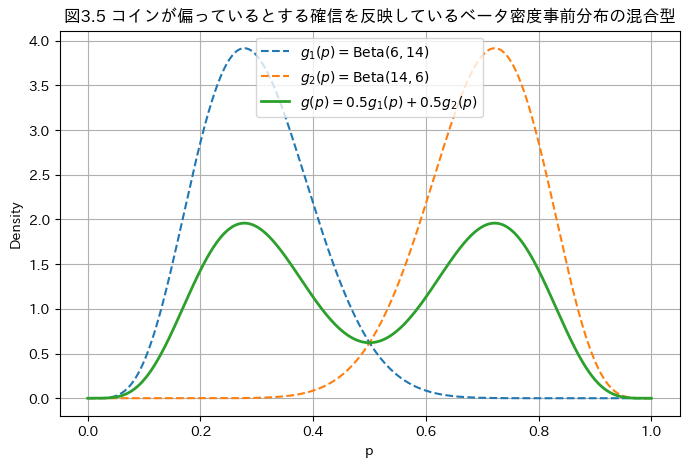

In [27]:
from scipy.stats import beta

# p の範囲
p = np.linspace(0, 1, 1000)

# パラメータ
a1, b1 = 6, 14
a2, b2 = 14, 6
gamma = 0.5

# 各ベータ密度
g1 = beta.pdf(p, a1, b1)
g2 = beta.pdf(p, a2, b2)

# 混合事前分布
g = gamma * g1 + (1 - gamma) * g2

# プロット
plt.figure(figsize=(8, 5))
plt.plot(p, g1, linestyle="--", label=r"$g_1(p)=\mathrm{Beta}(6,14)$")
plt.plot(p, g2, linestyle="--", label=r"$g_2(p)=\mathrm{Beta}(14,6)$")
plt.plot(p, g, linewidth=2, label=r"$g(p)=0.5 g_1(p)+0.5 g_2(p)$")

plt.xlabel("p")
plt.ylabel("Density")
plt.title("図3.5 コインが偏っているとする確信を反映しているベータ密度事前分布の混合型")
plt.legend()
plt.grid(True)


コインを $ n $ 回投げて、表が $ s $ 回、裏が $ f=n-s $ 回出るとする。

この割合の事後密度は次の混合型となる。

$ g(p|data) = \gamma(data) g_1(p|data) + (1-\gamma(data)) g_2(p|data) $

$ g_1 : beta(6+s, 14+f) $、 $ g_2: beta(14+s, 6+f) $

混合確率 $ \gamma(data) = \gamma f_1(s,f) / (\gamma f_1(s,f) + (1-\gamma)f_2(s,f)) $

ここで１０回コインを投げ、表が７回、裏が３回出るとする。
pの事後分布は以下のベータ分布の混合型となる。

$ g(p|data) = 0.093 beta(13,17) + 0.907 beta(21,9) $

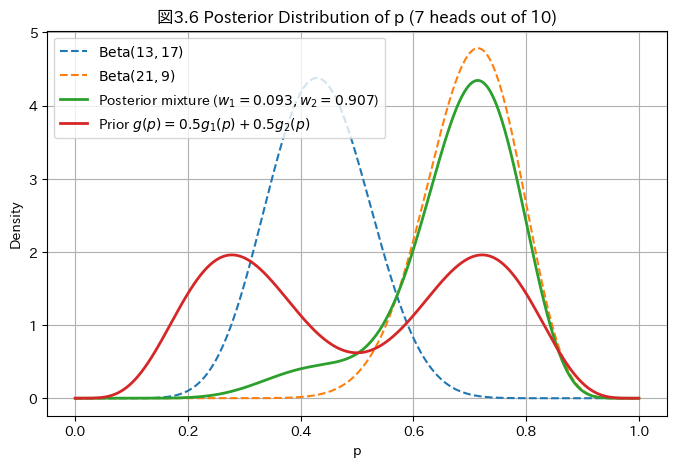

In [28]:
from scipy.special import beta as beta_func

# 観測データ
n = 10
y = 7

# 事前分布のパラメータ
a1, b1 = 6, 14
a2, b2 = 14, 6
gamma1 = 0.5
gamma2 = 0.5

# 事後ベータ分布のパラメータ
a1_post, b1_post = a1 + y, b1 + n - y   # Beta(13,17)
a2_post, b2_post = a2 + y, b2 + n - y   # Beta(21,9)

# 混合重みの更新（周辺尤度を考慮）
m1 = beta_func(a1_post, b1_post) / beta_func(a1, b1)
m2 = beta_func(a2_post, b2_post) / beta_func(a2, b2)

w1 = gamma1 * m1
w2 = gamma2 * m2
w1, w2 = w1 / (w1 + w2), w2 / (w1 + w2)

# p の範囲
p = np.linspace(0, 1, 1000)

# 各事後密度
g1_post = beta.pdf(p, a1_post, b1_post)
g2_post = beta.pdf(p, a2_post, b2_post)

# 混合事後分布
g_post = w1 * g1_post + w2 * g2_post

# プロット
plt.figure(figsize=(8, 5))
plt.plot(p, g1_post, linestyle="--",
         label=fr"$\mathrm{{Beta}}({a1_post},{b1_post})$")
plt.plot(p, g2_post, linestyle="--",
         label=fr"$\mathrm{{Beta}}({a2_post},{b2_post})$")
plt.plot(p, g_post, linewidth=2,
         label=fr"Posterior mixture ($w_1={w1:.3f}, w_2={w2:.3f}$)")

plt.plot(p, g, linewidth=2, label=r"Prior $g(p)=0.5 g_1(p)+0.5 g_2(p)$")

plt.xlabel("p")
plt.ylabel("Density")
plt.title("図3.6 Posterior Distribution of p (7 heads out of 10)")
plt.legend()
plt.grid(True)
plt.show()


### 3.6 コインの偏りについてのベイズ検定



コインに偏りがないかを検定する。yがパラメータnとpの二項分布に従うことを観測する。p=0.5 とする仮説Hを検定する。コインを２０回投げて、表が５回のみだった場合のp値を求め、有意水準0.05として検証するPythonプログラムの作成をお願いします。理解のためのグラフを作成するプログラムもお願いします。

In [29]:
import numpy as np
from scipy.stats import binom

n = 20
p = 0.5
y = 5

# 左側確率
p_left = binom.cdf(y, n, p)

# 両側検定（対称なので2倍）
p_value = 2 * p_left

print(f"p値 = {p_value:.5f}")

# 判定
alpha = 0.05
if p_value < alpha:
    print("帰無仮説は棄却される（コインは偏っている可能性）")
else:
    print("帰無仮説は棄却されない")

p値 = 0.04139
帰無仮説は棄却される（コインは偏っている可能性）


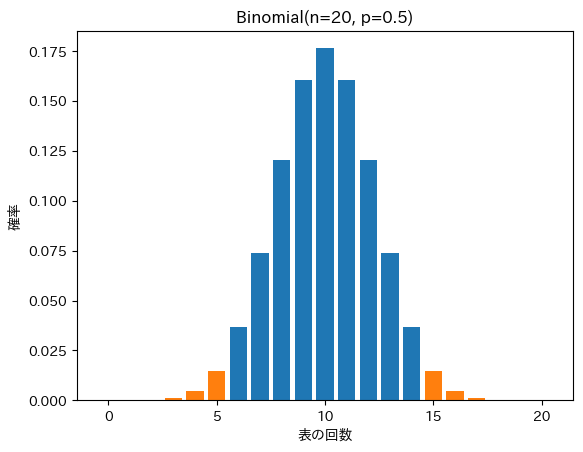

In [30]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 20
p = 0.5

x = np.arange(0, n+1)
pmf = binom.pmf(x, n, p)

plt.figure()
plt.bar(x, pmf)

# p値領域を強調
mask = (x <= 5) | (x >= 15)
plt.bar(x[mask], pmf[mask])

plt.xlabel("表の回数")
plt.ylabel("確率")
plt.title("Binomial(n=20, p=0.5)")

plt.show()

次に、ベイズの観点から、コインには偏りがない(p=0.5)か、偏りがある($ p /neq 0.5 $)の二つのモデルを考え、どちらにも1/2の確率を割り当てる。

事前分布は$ g(p) = 0.5 I (p=0.5) + 0.5 I (p /neq 0.5) g_1 (p) $ 

pにベータ事前分布 $ bata(a,a) $を割り当て、コインが偏っていると信じる場合の事前分布 (0,1) $ g_1(p) $ とする。

まずコインに偏りがあるばあいのpにベータ事前分布beta(10,10)を割り当てn=20回投げてy＝５回の表を観測するとすると、偏りについての事後確率を求める、Pythonプログラムと視覚化する。

In [31]:
import numpy as np
from scipy.special import comb, beta

# データ
n = 20
y = 5
a = 10

# 事前確率
prior_M0 = 0.5
prior_M1 = 0.5

# --- M0: p=0.5 ---
lik_M0 = comb(n, y) * (0.5 ** n)

# --- M1: Beta(10,10) ---
lik_M1 = comb(n, y) * beta(y + a, n - y + a) / beta(a, a)

# --- 事後確率 ---
posterior_M1 = (lik_M1 * prior_M1) / (lik_M0 * prior_M0 + lik_M1 * prior_M1)
posterior_M0 = 1 - posterior_M1

print(f"P(M1 | data) = {posterior_M1:.4f}")
print(f"P(M0 | data) = {posterior_M0:.4f}")

P(M1 | data) = 0.7198
P(M0 | data) = 0.2802


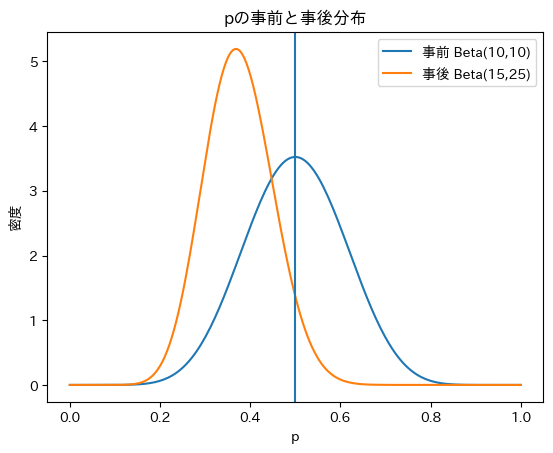

In [32]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

x = np.linspace(0, 1, 200)

# 事前と事後
prior = beta.pdf(x, 10, 10)
posterior = beta.pdf(x, 15, 25)

plt.figure()
plt.plot(x, prior, label="事前 Beta(10,10)")
plt.plot(x, posterior, label="事後 Beta(15,25)")

plt.axvline(0.5)  # 公平ライン

plt.legend()
plt.title("pの事前と事後分布")
plt.xlabel("p")
plt.ylabel("密度")

plt.show()

### 3.9 練習問題

### 3.9.1 コーシー・サンプリングモデル

ランダム標本 $ y_1, ... y_n $ が位置パラメータ $ \theta $、尺度 p からパラメータ $ l $ のコーシー密度に従うとする。

この $ \theta $ に一様事前分布を仮定する。（明示されていない場合の標準設定）

データとして $ 0, 10, 9, 8, 11, 3, 3, 8, 8, 11 $ を観測する。

$ g(\theta|data) \propto \prod_{i=1}^n 1/ (1 + (y_i - \theta)^2) $

1. 事後密度を計算せよ。

2. 密度をプロットせよ。

3. $ \theta $ の事後平均と事後標準偏差を計算せよ。




事後平均     = 8.6293
事後標準偏差 = 0.6454


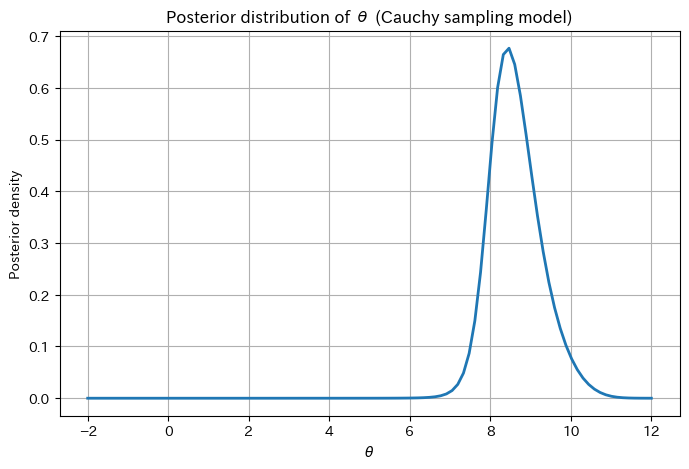

In [33]:
# データ
y = np.array([0, 10, 9, 8, 11, 3, 3, 8, 8, 11])
n = len(y)

# theta の評価点（十分広い範囲を取る）
theta = np.linspace(-2, 12, 100)

# 尤度（対数で計算してから戻す）
log_likelihood = np.zeros_like(theta)
for yi in y:
    log_likelihood -= np.log(1 + (yi - theta)**2)

# 事後密度（未正規化）
posterior_unnorm = np.exp(log_likelihood)

# 正規化
delta = theta[1] - theta[0]
posterior = posterior_unnorm / np.sum(posterior_unnorm * delta)

# 事後平均
post_mean = np.sum(theta * posterior * delta)

# 事後分散・標準偏差
post_var = np.sum((theta - post_mean)**2 * posterior * delta)
post_sd = np.sqrt(post_var)

print(f"事後平均     = {post_mean:.4f}")
print(f"事後標準偏差 = {post_sd:.4f}")

# プロット
plt.figure(figsize=(8, 5))
plt.plot(theta, posterior, linewidth=2)
plt.xlabel(r"$\theta$")
plt.ylabel("Posterior density")
plt.title("Posterior distribution of θ (Cauchy sampling model)")
plt.grid(True)
plt.show()


In [34]:
n

10

### 3.9.2 指数平均について検討する

ランダム標本が平均 $ \lambda $ の指数分布に従うとする。
標準的な無情報事前密度 $ g(\lambda) \propto 1/\lambda $ を仮定する。

1. $ \lambda $ を $ \theta = 1 / \lambda $ に変換すると、 $ \theta $ は形状パラメータ $ n $、尺度パラメータの逆数 $ (rate) $ が $ s $ のガンマ密度になることを証明せよ。

2. 寿命試験において、五つの電球が切れるまでの時間がそれぞれ、 $ 751, 594, 1213, 1120, 819 $ であった。$ \theta $ の事後分布から 1000 個の値を趣味レーションせよ。

3. この、シュミレーション標本を変換して、 $ \lambda $ の事後分布からのシュミレーション標本を抽出せよ。

4. $ \lambda $ が1000時間を超える事後確率を推定せよ。

* 観測データ

* 密度

* 事前分布（無情報雨事前）

* 変数変換

Text(0.5, 1.0, 'Exponential Distribution (lambda=2.0)')

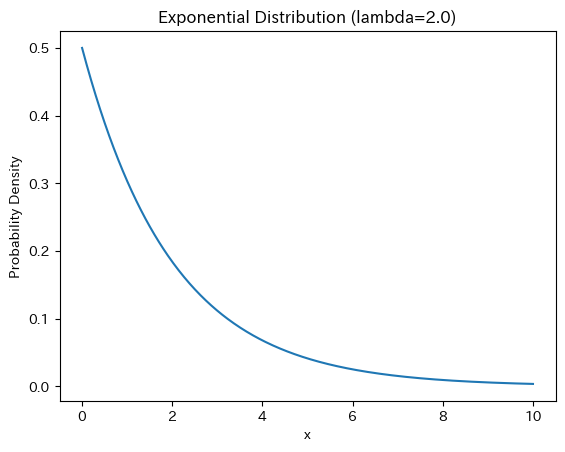

In [35]:
# パラメータ（平均）
lam = 2.0

# x 軸
x = np.linspace(0, 10, 500)

# 指数分布の確率密度関数
pdf = (1/lam)*np.exp(-x/lam)

plt.figure()
plt.plot(x,pdf)
plt.xlabel("x")
plt.ylabel("Probability Density")
plt.title(f"Exponential Distribution (lambda={lam})")


$ \theta = 1 /　\lambda  $ の事後分布がガンマ分布になることの証明

尤度関数

$ L(\lambda) = \prod_{i=1}^n 1/ \lambda exp(-y_i/ \lambda) = \lambda^{-n} exp(\sum y_i / \lambda) $

事後分布（未正規化）

$ p(\lambda | data) \propto \lambda^{-n+1} exp(-s/ \lambda), \qquad s= \sum y_i $

変数変換 $ \theta = 1 / \lambda $

ヤコビアン

$ | \frac{d \lambda}{ d \theta} | = \frac{1}{\theta^2} $

事後分布

$ p(\theta | data) \propto \theta^{n-1} exp(-s\theta) $

$ \theta \sim Gamma(shape=n, rate=s) $

In [36]:
from scipy.stats import gamma

y = np.array([751, 594, 1213, 1120, 819])

n = len(y)
s = y.sum()



In [37]:
np.random.seed(0)

lambda_samples = np.random.gamma(shape=n, scale=1/s, size=1000)
lambda_samples = 1/lambda_samples

Text(0.5, 1.0, 'Posterior samples of Lambda (Gamma posterior)')

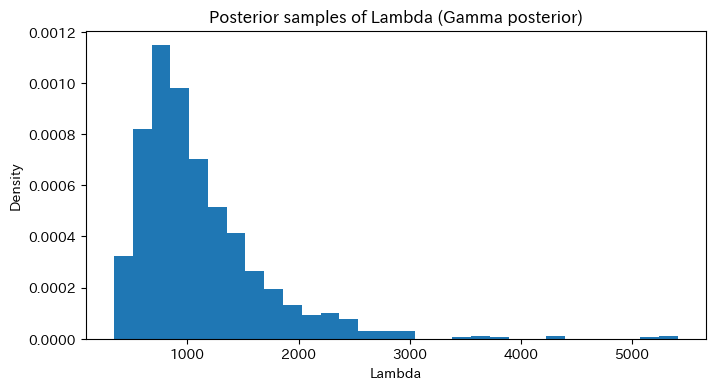

In [38]:
plt.figure(figsize=(8,4))
plt.hist(lambda_samples, bins=30, density=True)
plt.xlabel("Lambda")
plt.ylabel("Density")
plt.title("Posterior samples of Lambda (Gamma posterior)")

In [39]:
prob_lambda_gt_1000 = np.mean(lambda_samples > 1000)
print(f"P(lambda > 1000) = {prob_lambda_gt_1000:.4f}")

P(lambda > 1000) = 0.4580


### 3.9.4  離散一様密度の上昇について検討する

上界 N が道である集合 {1,2,..., N} 上の一様分布から独立標本 $ y
_1, y_2,...,y_n $ を抽出する。
ここで B が基地である値、1,..., B 上の N に一様事前分布を仮定する。

ある街である旅行者がタクシーを待っている。
待っている間に 5 台のタクシーが通り過ぎるが、それぞれに 43, 24, 100, 35, 85 という番号がついている。
そこで、この街のタクシーには 1 から N までの番号が振り分けられていると考えられる。
さらにこの旅行者がある特定の時点で目にするタクシーはどんな番号のものでもあり得るわけで、どのタクシーがあれ現れてもそれは独立事象である。
また、タクシーの台数は 200 を超えない。

1. 可能な値のグリッドを設定して、N の事後確率を求めよ。

2. N の事後平均と事後標準偏差を求めよ。

3. この町のタクシーの台数が 150 を超える確率を求めよ。

尤度関数

離散一様分布

$ P(y_i | N) = $ $ \begin{cases} \frac{1}{N} & (y_i \leq N) \\ 0 &(y_i > N) \end{cases} $

独立性

$ L(N|y) = $ $ \begin{cases} N^{-n} & (N \geq max(y)) \\ 0 & (N < max(y)) \end{cases} $

事後分布

事前が一様なので

$ P(N|y) \propto $ $ \begin{cases} N^{-n} & max(y) \leq N \leq B \\ 0 & otherwise \end{cases} $

$ max(y)=100, n=5, B=200 $

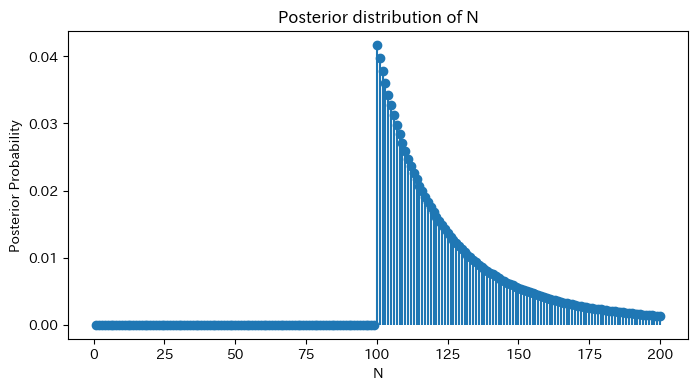

事後平均: 123.976
事後標準偏差: 22.775
P(N > 150 | data) = 0.1388


In [40]:
# ===== データ =====
y = np.array([4, 40, 35, 5,100])
n = len(y)
B = 200

# ===== N のグリッド =====
N_grid = np.arange(1, B + 1)

# ===== 尤度 =====
likelihood = np.zeros_like(N_grid, dtype=float)
valid = N_grid >= y.max()
likelihood[valid] = N_grid[valid].astype(float) ** (-n)

# ===== 事前分布（一様）=====
prior = np.ones_like(N_grid, dtype=float) / B

# ===== 事後分布 =====
posterior = likelihood * prior
posterior /= posterior.sum()  # 正規化

# ===== 1. 事後分布の可視化 =====
plt.figure(figsize=(8, 4))
plt.stem(N_grid, posterior, basefmt=" ")
plt.xlabel("N")
plt.ylabel("Posterior Probability")
plt.title("Posterior distribution of N")
plt.show()

# ===== 2. 事後平均・事後標準偏差 =====
post_mean = np.sum(N_grid * posterior)
post_sd = np.sqrt(np.sum((N_grid - post_mean)**2 * posterior))

print(f"事後平均: {post_mean:.3f}")
print(f"事後標準偏差: {post_sd:.3f}")

# ===== 3. P(N > 150 | data) =====
prob_gt_150 = posterior[N_grid > 150].sum()
print(f"P(N > 150 | data) = {prob_gt_150:.4f}")


### 3.9.4 ベイズの頑健性

偏りがないと信じるコインを投げようとする。
表が出る確率を p と表す。
コインには偏りがないほとんど無い可能性が高い。
量的には、 $ P(0.44 < p < 0.56) = 0.9 $ となる。
この時、p について次の二つの事前分布を検討せよ。

P1:ベータ分布 $ beta(100,100)に従うp

P2:複合事前分ぷに従うp $ g(p) = 0.9 f_B (p:500,500) + 0.1 f_B(p:1,1) $

(a) P1とP2それぞれの事前分布から 1000 個の値をシュミレーションせよ。さらにシュミレーション標本をようやくすることで、どちらの事前分布も、コイン投げの確率 p の事前の確信の適合することを示せ。

分布の形の違い

P1
* 単峰
* 0.5付近に綺麗に集中
* 信念が素直に一つ

P2
* 中心は非常に鋭い (Beta(500, 500))
* 橋にも裾が残る (Beta(1,1))
* 観測データが想定外でも、破綻しにくい




P1: P(0.44 < p < 0.56) ≈ 0.928
P2: P(0.44 < p < 0.56) ≈ 0.917


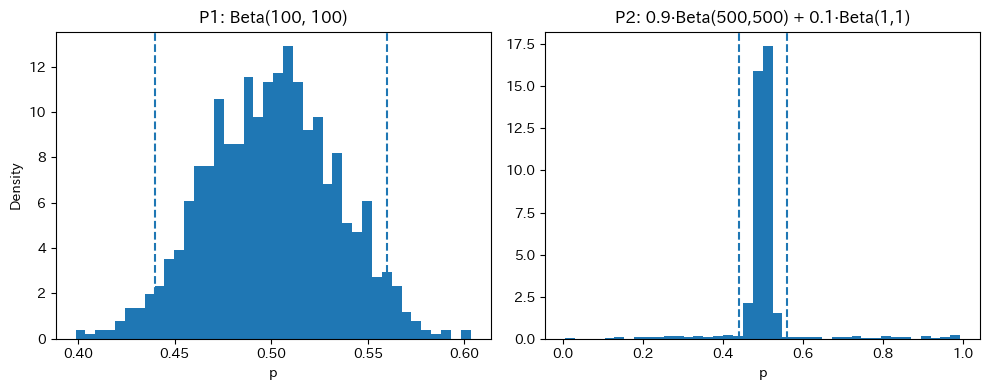

In [41]:
# ====== 乱数の再現性 ======
np.random.seed(123)

# ====== サンプルサイズ ======
N = 1000

# ====== P1: Beta(100, 100) ======
p1_samples = beta.rvs(100, 100, size=N)

# ====== P2: 混合事前分布 ======
# 90%: Beta(500,500), 10%: Beta(1,1)
mix_indicator = np.random.rand(N) < 0.9

p2_samples = np.empty(N)
p2_samples[mix_indicator] = beta.rvs(500, 500, size=mix_indicator.sum())
p2_samples[~mix_indicator] = beta.rvs(1, 1, size=(~mix_indicator).sum())

# ====== 確率の評価 ======
def prob_interval(samples, low=0.44, high=0.56):
    return np.mean((samples > low) & (samples < high))

p1_prob = prob_interval(p1_samples)
p2_prob = prob_interval(p2_samples)

print(f"P1: P(0.44 < p < 0.56) ≈ {p1_prob:.3f}")
print(f"P2: P(0.44 < p < 0.56) ≈ {p2_prob:.3f}")

# ====== ヒストグラム ======
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.hist(p1_samples, bins=40, density=True)
plt.axvline(0.44, linestyle='--')
plt.axvline(0.56, linestyle='--')
plt.title("P1: Beta(100, 100)")
plt.xlabel("p")
plt.ylabel("Density")

plt.subplot(1, 2, 2)
plt.hist(p2_samples, bins=40, density=True)
plt.axvline(0.44, linestyle='--')
plt.axvline(0.56, linestyle='--')
plt.title("P2: 0.9·Beta(500,500) + 0.1·Beta(1,1)")
plt.xlabel("p")

plt.tight_layout()
plt.show()


(b) コインを１００回投げて表が４５回出るとする。
事前分布P1とP2に基づく事後分布から１０００回の値をシュミレーションで抽出し、９０％確率区間を求めよ。

尤度：

$ p(y|p) \propto p^{45}(1-p)^{55} $

P1: Beta(100,100)

$ p|data \sim Beta(100+45,100+45) = Beta(145, 145) $

P2: 

各成分の事後

成分１：

$ Beta(500+45, 500+55) = Beta(545, 555) $

成分２：
$ Beta(1+45, 1+55) = Beta(46,56) $

混合重みの更新（ベイズ更新）

事後重み：

$ w_k \propto w_k^{(prior)} \times {周辺尤度} $

周辺尤度（ベータ　ー　二項）：

$ m(y) = \frac{B(\alpha+y, \beta+n-y)}{B(\alpha, \beta)} $

In [42]:
from scipy.special import betaln

np.random.seed(123)

# ====== 観測データ ======
n = 100
y = 45
Nsim = 1000

# =====================================================
# P1: Beta(100,100) → Beta(145,155)
# =====================================================
p1_post_samples = beta.rvs(145, 155, size=Nsim)

p1_ci = np.percentile(p1_post_samples, [5, 95])

# =====================================================
# P2: 混合事前
# =====================================================
# 事前重み
w_prior = np.array([0.9, 0.1])

# 事前パラメータ
alpha_prior = np.array([500, 1])
beta_prior  = np.array([500, 1])

# 事後パラメータ
alpha_post = alpha_prior + y
beta_post  = beta_prior + (n - y)

# 周辺尤度（logで計算）
log_marginal = (
    betaln(alpha_post, beta_post)
    - betaln(alpha_prior, beta_prior)
)

# 事後重み
log_weights = np.log(w_prior) + log_marginal
weights_post = np.exp(log_weights - log_weights.max())
weights_post /= weights_post.sum()

print("P2 posterior weights:", weights_post)

# 混合事後からサンプリング
component = np.random.choice([0, 1], size=Nsim, p=weights_post)

p2_post_samples = np.empty(Nsim)
p2_post_samples[component == 0] = beta.rvs(alpha_post[0], beta_post[0],
                                           size=(component == 0).sum())
p2_post_samples[component == 1] = beta.rvs(alpha_post[1], beta_post[1],
                                           size=(component == 1).sum())

p2_ci = np.percentile(p2_post_samples, [5, 95])

# ====== 結果表示 ======
print(f"P1 90% credible interval: [{p1_ci[0]:.3f}, {p1_ci[1]:.3f}]")
print(f"P2 90% credible interval: [{p2_ci[0]:.3f}, {p2_ci[1]:.3f}]")


P2 posterior weights: [0.97776153 0.02223847]
P1 90% credible interval: [0.439, 0.528]
P2 90% credible interval: [0.469, 0.518]


(c) コインを１００回投げて表が３０回しか出ないとする。改めて事前分ぷをP1とP2に基づく事後分布から１０００個のシュミレーションで抽出し、９０％確率区間を求めよ。

In [43]:
np.random.seed(123)

# ====== 観測データ ======
n = 100
y = 30
Nsim = 1000

# =====================================================
# P1: Beta(100,100) → Beta(130,170)
# =====================================================
p1_post_samples = beta.rvs(130, 170, size=Nsim)
p1_ci = np.percentile(p1_post_samples, [5, 95])

# =====================================================
# P2: 混合事前
# =====================================================
w_prior = np.array([0.9, 0.1])
alpha_prior = np.array([500, 1])
beta_prior  = np.array([500, 1])

alpha_post = alpha_prior + y
beta_post  = beta_prior + (n - y)

# 周辺尤度（log）
log_marginal = (
    betaln(alpha_post, beta_post)
    - betaln(alpha_prior, beta_prior)
)

log_weights = np.log(w_prior) + log_marginal
weights_post = np.exp(log_weights - log_weights.max())
weights_post /= weights_post.sum()

print("P2 posterior weights:", weights_post)

# 混合事後からサンプリング
component = np.random.choice([0, 1], size=Nsim, p=weights_post)

p2_post_samples = np.empty(Nsim)
p2_post_samples[component == 0] = beta.rvs(alpha_post[0], beta_post[0],
                                           size=(component == 0).sum())
p2_post_samples[component == 1] = beta.rvs(alpha_post[1], beta_post[1],
                                           size=(component == 1).sum())

p2_ci = np.percentile(p2_post_samples, [5, 95])

# ====== 結果 ======
print(f"P1 90% credible interval: [{p1_ci[0]:.3f}, {p1_ci[1]:.3f}]")
print(f"P2 90% credible interval: [{p2_ci[0]:.3f}, {p2_ci[1]:.3f}]")


P2 posterior weights: [0.0399307 0.9600693]
P1 90% credible interval: [0.390, 0.479]
P2 90% credible interval: [0.231, 0.393]


(d) ここでの(b)、(c)の結果から、それぞれの事前密度選択に対する推論の頑健性を確認せよ。

P1（強い単一事前）
* 区間がまだ0.５より
* データが極端でも、「コインはそこまで偏っていないはず」

P2（頑健事前）
* Beta(1,1)成分の重みが急増
* 区間が大きく左へ移動、「データを素直に信じる方向へ」

### 3.9.5 割合の検定

ラインの標準超感覚的知能テスト（ESP）で、各々のカードには円、四角、波線、十字、星の図形が描かれている。
ひと束のカードの中からランダムに一枚を取り上げ、そのカードに描かれている図形を推測する。
この実験を20回繰り返し、カードの図形を正しく言い当てる回数 y を記録する。
p をカードの図形を正しく当てる確率とする。
EPSがあるわけでなく単なる勘で当たる確率を 0.2 とする。
本当にEPSがあるかどうかを確認するため、仮説 $ H: p=0.2 $ を検定する。

(a) 仮に　$ y=8 $ 枚のカードを言い当てるとして、pの値を計算せよ。

In [44]:
# ===== データ =====
n = 20   # 試行回数
y = 8    # 正解回数

# ===== p の推定値（最尤推定）=====
p_hat = y / n

print(f"推定された p の値: {p_hat:.3f}")


推定された p の値: 0.400


(b) あらかじめ勘で当たる確率 $ p= 0.2 $の事前確率を 0.5 とする。
$ p \neq 0.2 $ で無い場合には、この割合にベータ分布 $ beta(1,4) $を割り当てる。

仮説 H の事後確率を計算せよ。その結果を (a) で求めたP値と比較せよ。

事後確率は

$ P(H_0 | y) = \frac{P(y|H_0)P(H_0)}{P(y|H_0)P(H_0)+P(y|H_1)+P(y|H_1)P(N_1)} $



In [45]:
from scipy.special import beta, comb

# ===== データ =====
n = 20
y = 8

# ===== 事前確率 =====
prior_H0 = 0.5
prior_H1 = 0.5

# ===== 周辺尤度 =====
# H0 : p = 0.2
p0 = 0.2
marginal_H0 = binom.pmf(y, n, p0)

# H1 : p ~ Beta(1,4)
alpha, beta_param = 1, 4
marginal_H1 = (
    comb(n,y) *
    beta(y+alpha,n-y+beta_param)/
    beta(alpha,beta_param)
)

# ===== 事後確率 =====
posterior_H0 = (
    marginal_H0 * prior_H0 /
    (marginal_H0 * prior_H0 + marginal_H1 * prior_H1)
)

# ===== 出力 =====
print(f"P(H0 | data) = {posterior_H0:.4f}")
print(f"P(H1 | data) = {1 - posterior_H0:.4f}")


P(H0 | data) = 0.3410
P(H1 | data) = 0.6590


In [46]:
# ===== データ =====
n = 20
y = 8

# ===== 事前確率 =====
prior_H0 = 0.5
prior_H1 = 0.5

# ===== 周辺尤度 =====
p0 = 0.2
marginal_H0 = binom.pmf(y,n,p0)

# H1: p ~ Beta(1,4)
alpha, beta_param = 1, 4
marginal_H1 = (
    comb(n, y) *
    beta(y + alpha, n - y + beta_param) /
    beta(alpha, beta_param)
)

# ===== 事後確率 =====
posterior_H0 = (
    marginal_H0 * prior_H0 /
    (marginal_H0 * prior_H0 + marginal_H1 * prior_H1)
)

# ===== 出力 =====
print(f"P(y | H0) = {marginal_H0:.6f}")
print(f"P(y | H1) = {marginal_H1:.6f}")
print(f"P(H0 | data) = {posterior_H0:.4f}")
print(f"P(H1 | data) = {1 - posterior_H0:.4f}")


P(y | H0) = 0.022161
P(y | H1) = 0.042819
P(H0 | data) = 0.3410
P(H1 | data) = 0.6590


(c) 次の事前分布のそれぞれについてHの事後確率を計算せよ。

(1) $ p \sim beta(0.5, 2) $
(2) $ p \sim beta(2,8) $
(3) $ p \sim beta(8,32) $

In [47]:
import numpy as np
from scipy.stats import binom
from scipy.special import beta, comb

# ===== データ =====
n = 20
y = 8
p0 = 0.2

prior_H0 = 0.5
prior_H1 = 0.5

# ===== H0 の周辺尤度 =====
marginal_H0 = binom.pmf(y, n, p0)

# ===== 各事前分布 =====
priors = {
    "Beta(0.5, 2)": (0.5, 2),
    "Beta(2, 8)": (2, 8),
    "Beta(8, 32)": (8, 32)
}

print(f"P(y | H0) = {marginal_H0:.6e}\n")

for name, (a, b) in priors.items():
    marginal_H1 = (
        comb(n, y) *
        beta(y + a, n - y + b) /
        beta(a, b)
    )

    posterior_H0 = (
        marginal_H0 * prior_H0 /
        (marginal_H0 * prior_H0 + marginal_H1 * prior_H1)
    )

    print(f"{name:12s} : P(H0 | data) = {posterior_H0:.4f}")


P(y | H0) = 2.216088e-02

Beta(0.5, 2) : P(H0 | data) = 0.3901
Beta(2, 8)   : P(H0 | data) = 0.3286
Beta(8, 32)  : P(H0 | data) = 0.3855


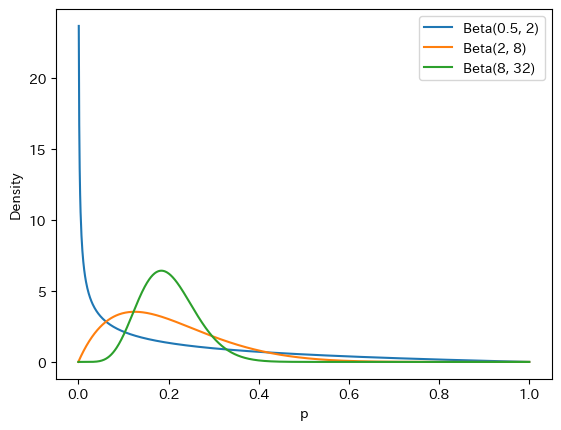

In [48]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta

# p range
p = np.linspace(0, 1, 1000)

# Beta distributions
pdf1 = beta.pdf(p, 0.5, 2)
pdf2 = beta.pdf(p, 2, 8)
pdf3 = beta.pdf(p, 8, 32)

# Plot
plt.figure()
plt.plot(p, pdf1, label="Beta(0.5, 2)")
plt.plot(p, pdf2, label="Beta(2, 8)")
plt.plot(p, pdf3, label="Beta(8, 32)")
plt.xlabel("p")
plt.ylabel("Density")
plt.legend()
plt.show()


(d) ベイズ法による計算結果に基づくと $ y = 8 $ という的中率が本当にESPがあるとする有力な証拠になると思うか、説明せよ。

ベイズ法による計算では、

帰無仮説

$ H_0 : p = 0.2 $

に対する事後確率は：

$ P(H_0|y=8) \approx 0.3 \sim 0.4 $

これは、２０回中８回的中という結果を観測した後でも、「EPSが存在しない（単なる勘である）」可能性が**なお３０〜４０％程度残っている**ことを意味する。

EPSの「有力な証拠」と言えるか？

有力な証拠とは言い難い。


### 3.9.6 グループ化データから検討する

高速道路を時速７０マイルの速度を維持して運転する。
ある日、一台の車を追い越し、逆に１７台に追い越された。
速度は平均 $ \mu $ は未知だが、標準偏差 $ \sigma = 10 $ の正規分布であるとする。
仮に s 台の車を追い越し、f 台の車に追い越されるとすると $ \mu $ の尤度は次式になる。

$ L(\mu) \propto \Phi(70,\mu, \sigma)^s (1 - \Phi(70, \mu, \sigma))^f $

ここで、$ \Phi(y,\mu,\sigma) $ は、平均 $ \mu $ で標準偏差 $ \sigma $ の正規分布の cdf である。

未知の $ \mu $ には平坦な事前密度を当てはめる。

(a) s=1 かつ f=17 として $ \mu $ の事後密度をプロットせよ。

Text(0.5, 1.0, 'Posterior of μ given s=1, f=17 (flat prior)')

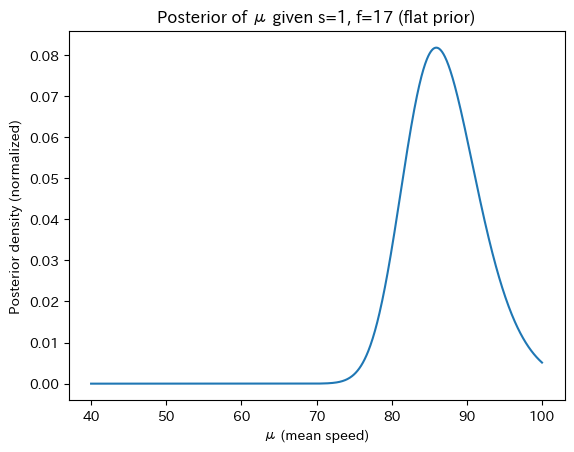

In [70]:
# ===== Given parameters =====
sigma = 10
s = 1    # number of cars overtaken
f = 17   # number of cars that overtook us
v0 = 70  # our speed

# ===== Grid for mu =====
mu = np.linspace(40, 100, 1000)

# ===== Likelihood (proportional to posterior due to flat prior) =====
Phi = norm.cdf(v0, loc=mu, scale=sigma)
likelihood = (Phi ** s) * ((1 - Phi) ** f)

# Normalize for plotting
posterior = likelihood / np.trapz(likelihood, mu)

# ===== Plot =====
plt.figure()
plt.plot(mu, posterior)
plt.xlabel("μ (mean speed)")
plt.ylabel("Posterior density (normalized)")
plt.title("Posterior of μ given s=1, f=17 (flat prior)")



(a) $ s = 1 $、$ f=17 $ として、$ \mu $ の事後密度をプロットせよ


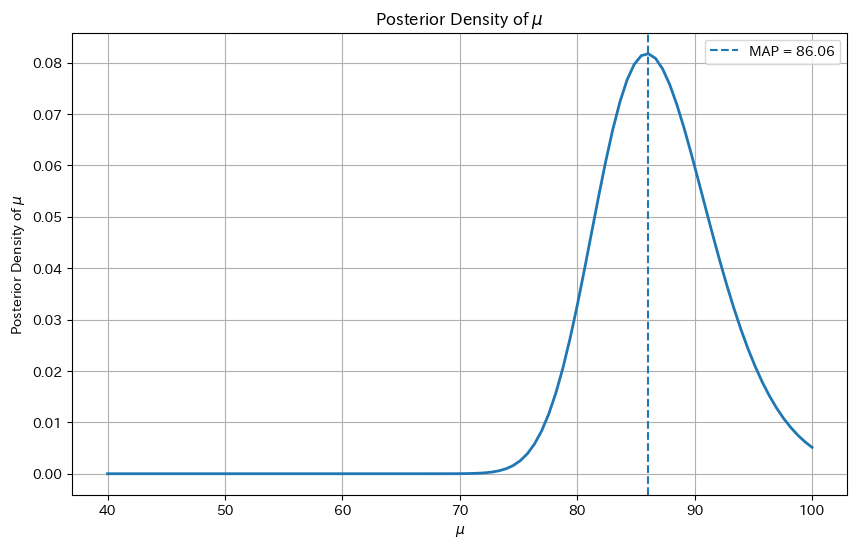

In [69]:
# データ

s = 1 #追い越した台数
f = 17 #追い越された台数
sigma = 10

# mu の範囲
mu = np.linspace(40,100, 100)

# 尤度（＝事後密度の比例形）
Phi = norm.cdf(70,loc=mu, scale=sigma)
posterior_unnormalized = (Phi**s)*((1-Phi)**f)

# 正規化
posterior = posterior_unnormalized / np.trapz(posterior_unnormalized, mu)

# 最尤点
mu_map = mu[np.argmax(posterior)]

# Plot
plt.figure(figsize=(10,6))

plt.plot(mu, posterior, linewidth=2)
plt.axvline(
    mu_map,
    linestyle="--",
    label=f"MAP = {mu_map:.2f}"
)
plt.xlabel(r"$\mu$")
plt.ylabel(r"Posterior Density of $\mu$")
plt.title(r"Posterior Density of $\mu$")
plt.grid(True)
plt.legend()

(b) (a)で求めた密度を使って、$ \mu $ の事後平均を計算せよ。

In [50]:
# ===== Posterior mean =====
posterior_mean = np.trapz(mu * posterior, mu)

posterior_mean

86.88246899759129

(c) この高速道路を走る車の平均速度が時速８０マイルを超える確率を計算せよ。

In [51]:
# ===== Probability that mu > 80 =====
mask = mu > 80
prob_mu_gt_80 = np.trapz(posterior[mask], mu[mask])

prob_mu_gt_80


0.9286445624508082

### 3.9.7 死亡率について混合事前分布を利用して検討する。

 心臓移植手術の事例で、ある病院の死亡率 $ \lambda $ を推定したい。
 事前分布を構成するために、２人の専門家と相談する。
 一人目の専門家は $ \lambda $ はガンマ分布 $ gamma(1.5, 1000) $ に、もう一人は $ gamma(7,1000) $ に従うと考えている。
 どちらの専門家の意見も同等に受け入れ、事前の確信は次の混合事前分布で表すことにする。

 $ g(\lambda) = 0.5 g_1(\lambda) + 0.5 g_2(\lambda) $

 (a) $ \lambda $ の事前密度のグラフを作成せよ。

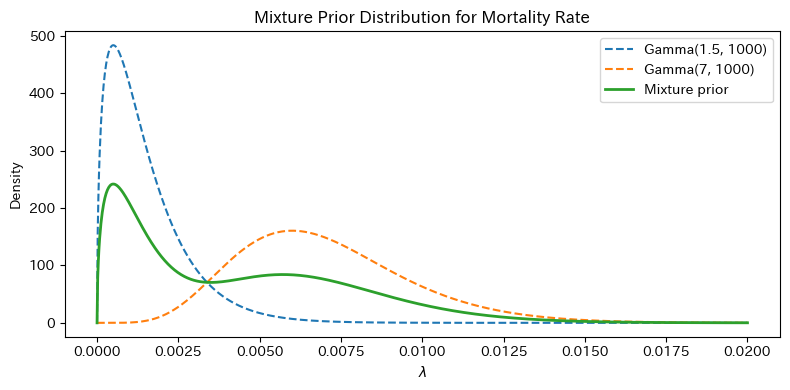

In [52]:
# SciPyのgammaは、shape = alpha, scle = 1/beta を使う点に注意
from scipy.stats import gamma

# ===== パラメータ =====
alpha1, beta1 = 1.5, 1000   # 専門家1
alpha2, beta2 = 7.0, 1000   # 専門家2
w1, w2 = 0.5, 0.5           # 混合比

# ===== λ のグリッド =====
lam = np.linspace(0, 0.02, 1000)

# ===== 各事前密度 =====
g1 = gamma.pdf(lam, a=alpha1, scale=1/beta1)
g2 = gamma.pdf(lam, a=alpha2, scale=1/beta2)

# ===== 混合事前密度 =====
g_mix = w1 * g1 + w2 * g2

# ===== プロット =====
plt.figure(figsize=(8, 4))
plt.plot(lam, g1, linestyle="--", label="Gamma(1.5, 1000)")
plt.plot(lam, g2, linestyle="--", label="Gamma(7, 1000)")
plt.plot(lam, g_mix, linewidth=2, label="Mixture prior")

plt.xlabel(r"$\lambda$")
plt.ylabel("Density")
plt.title("Mixture Prior Distribution for Mortality Rate")
plt.legend()
plt.tight_layout()
plt.show()


(b) この病院の手術数が $ e=1767 $ で、観測された死亡数が $ y_{obs}=4 $ であるとき、事後分布を求めよ。


死亡数

$ y_{obs} \sim Poisson(e \lambda) $

Updated mixture weights: [0.7597182 0.2402818]


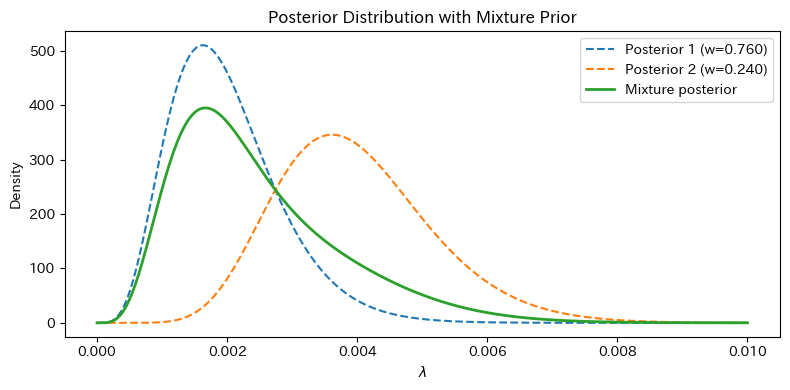

In [53]:

from scipy.special import gamma as gamma_func

# ===== 観測データ =====
e = 1767
y_obs = 4

# ===== 事前パラメータ =====
alpha = np.array([1.5, 7.0])
beta = np.array([1000.0, 1000.0])
w = np.array([0.5, 0.5])

# ===== 事後パラメータ =====
alpha_post = alpha + y_obs
beta_post = beta + e

# ===== 重みの更新 =====
unnorm_w = (
    w
    * (beta ** alpha)
    / (beta_post ** alpha_post)
    * gamma_func(alpha_post)
    / gamma_func(alpha)
)
w_post = unnorm_w / np.sum(unnorm_w)

print("Updated mixture weights:", w_post)

# ===== λ のグリッド =====
lam = np.linspace(0, 0.01, 1000)

# ===== 事後密度 =====
post1 = gamma.pdf(lam, a=alpha_post[0], scale=1/beta_post[0])
post2 = gamma.pdf(lam, a=alpha_post[1], scale=1/beta_post[1])
post_mix = w_post[0]*post1 + w_post[1]*post2

# ===== プロット =====
plt.figure(figsize=(8, 4))
plt.plot(lam, post1, linestyle="--",
         label=f"Posterior 1 (w={w_post[0]:.3f})")
plt.plot(lam, post2, linestyle="--",
         label=f"Posterior 2 (w={w_post[1]:.3f})")
plt.plot(lam, post_mix, linewidth=2, label="Mixture posterior")

plt.xlabel(r"$\lambda$")
plt.ylabel("Density")
plt.title("Posterior Distribution with Mixture Prior")
plt.legend()
plt.tight_layout()
plt.show()


(d) 死亡率 $ \lambda $ が 0.005 を超える確率を求めよ。

In [54]:
# ===== 観測データ =====
e = 1767
y_obs = 4
c = 0.005

# ===== 事前パラメータ =====
alpha = np.array([1.5, 7.0])
beta = np.array([1000.0, 1000.0])
w = np.array([0.5, 0.5])

# ===== 事後パラメータ =====
alpha_post = alpha + y_obs
beta_post = beta + e

# ===== 重み更新 =====
unnorm_w = (
    w
    * (beta ** alpha)
    / (beta_post ** alpha_post)
    * gamma_func(alpha_post)
    / gamma_func(alpha)
)
w_post = unnorm_w / np.sum(unnorm_w)

# ===== 各成分の超過確率 =====
p1 = 1 - gamma.cdf(c, a=alpha_post[0], scale=1/beta_post[0])
p2 = 1 - gamma.cdf(c, a=alpha_post[1], scale=1/beta_post[1])

# ===== 混合事後確率 =====
p_mix = w_post[0] * p1 + w_post[1] * p2

print(f"P(lambda > {c} | data) = {p_mix:.6f}")


P(lambda > 0.005 | data) = 0.047665


### 3.9.8 選択データに基づく指数平均について検討する。

寿命が平均 $ \lambda $ の指数分布に従う電球を１２個テストする。
全ての電球の検分が行われるが、あいにく４番目に短い寿命時間である $ y_4 $ の 100時間と、8番目 $ y_8 $ の300時間しか観測できない。

(a) $ \lambda $ に　$ 1/ \lambda $ に比例する無情報雨事前分布を割り当てるとする。事後分布をプロットせよ。

* 電球の寿命 $ Y $ は平均 $ \lambda $ の指数分布。

    * $ f(y| \lambda) = \frac{1}{\lambda} exp(- \frac{y}{\lambda}) $

* 電球は１２個

* 観測できたのは、
    * 4番目の故障時刻： $ y_4 = 100 $
    * 8番目の故障時刻： $ y_8 = 300 $

100時間までに４個故障

100 - 300時間の間にさらに４個故障

300時間時点で４個は未故障（右打ち切り）

尤度関数（指数分布の性質）

指数分布では、順序データの場合でも、総試験時間（Total Time on Test）だけでも尤度が決まる。

$ T = 4 \times 100 + 4 \times 300 + 4 \times 300 = 2800 $

故障数は８個なので、

$ L(\lambda) \propto \lambda^{-8} exp(- 2800/\lambda) $

事前分布：無用法事前分布

$ g(\lambda) \propto 1/\lambda $

事後分布：

$ \pi(\lambda|data) \propto \lambda^{-9} exp(-2800/\lambda) $

これは逆ガンマ分布

$ \lambda \sim Inv-Gammna(\alpha=8, \beta=2800) $


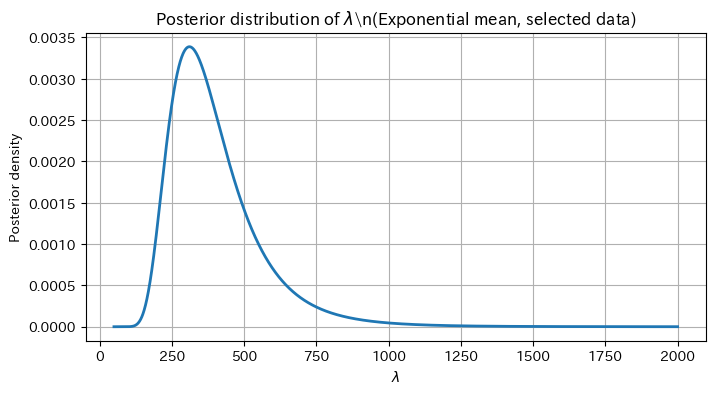

In [55]:
from scipy.stats import invgamma

# ===== Given data =====
n_fail = 8          # number of observed failures
T = 2800            # total time on test

# ===== Posterior parameters =====
alpha = n_fail      # shape
beta = T            # scale

# ===== Grid for lambda =====
lam = np.linspace(50, 2000, 2000)

# ===== Posterior density =====
posterior = invgamma.pdf(lam, a=alpha, scale=beta)

# ===== Plot =====
plt.figure(figsize=(8, 4))
plt.plot(lam, posterior, lw=2)
plt.xlabel(r"$ \lambda $")
plt.ylabel("Posterior density")
plt.title(r"Posterior distribution of $\lambda$\n(Exponential mean, selected data)")
plt.grid(True)
plt.show()


(b) $ \lambda $ の事後平均と、標準偏差を計算せよ。

In [56]:
from scipy.stats import invgamma

# ===== Posterior parameters =====
alpha = 8
beta = 2800

# ===== Posterior mean and SD =====
posterior_mean = beta / (alpha - 1)
posterior_var = beta**2 / ((alpha - 1)**2 * (alpha - 2))
posterior_sd = np.sqrt(posterior_var)

posterior_mean, posterior_sd


(400.0, 163.29931618554522)

(c) 平均寿命が 300時間から500時間である確率を求めよ。

In [57]:
from scipy.stats import invgamma

# ===== Posterior parameters =====
alpha = 8
beta = 2800

# ===== Probability calculation =====
prob = invgamma.cdf(500, a=alpha, scale=beta) \
     - invgamma.cdf(300, a=alpha, scale=beta)

prob


0.510648242624445

In [58]:
samples = invgamma.rvs(a=alpha, scale=beta, size=100000)
np.mean((samples >= 300) & (samples <= 500))


0.51213

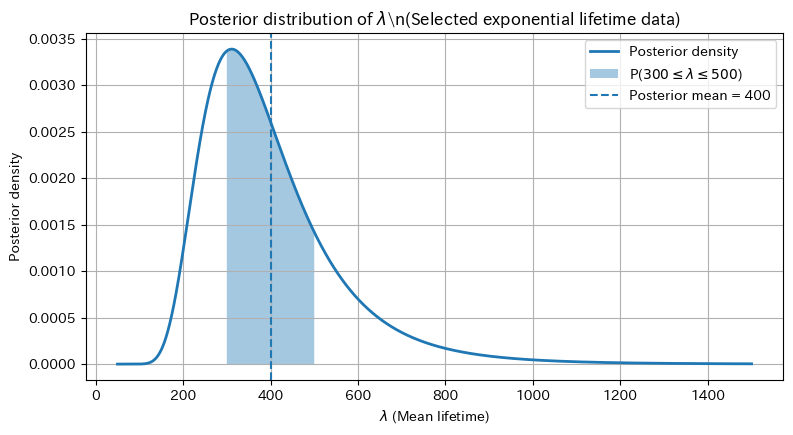

In [59]:
from scipy.stats import invgamma

# ===== Posterior parameters =====
alpha = 8
beta = 2800

# ===== Grid for lambda =====
lam = np.linspace(50, 1500, 3000)
posterior = invgamma.pdf(lam, a=alpha, scale=beta)

# ===== Interval of interest =====
lam_fill = np.linspace(300, 500, 1000)
posterior_fill = invgamma.pdf(lam_fill, a=alpha, scale=beta)

# ===== Posterior mean =====
posterior_mean = beta / (alpha - 1)

# ===== Plot =====
plt.figure(figsize=(9, 4.5))

plt.plot(lam, posterior, lw=2, label="Posterior density")
plt.fill_between(lam_fill, posterior_fill, alpha=0.4,
                 label=r"P($ 300  \leq  \lambda \leq  500 $)")
plt.axvline(posterior_mean, linestyle="--",
            label=f"Posterior mean = {posterior_mean:.0f}")

plt.xlabel(r"$\lambda$ (Mean lifetime)")
plt.ylabel("Posterior density")
plt.title(r"Posterior distribution of $\lambda$\n(Selected exponential lifetime data)")
plt.legend()
plt.grid(True)

plt.show()
